# 02 · Exploratory analysis: rare-earth imports from China and wind power

**Assignment 5, steps 2–4.** Univariate, bivariate and multivariate analysis, plus hypothesis testing, of the Assignment 4 database.
Functions live in [`src/analysis/`](../src/analysis/): `exploratory.py` (loading, describing),
`statistical.py` (correlation, partial correlation, regression) and `charts.py` (figures).

**Business question:** does the build-out of wind power drive countries' demand for Chinese rare earths,
and how exposed are buyers to a concentrated supplier?

Charts are saved to `docs/figures/` only when the notebook runs on the real database.

In [1]:
import pandas as pd
from IPython.display import display

from src.analysis import charts as ch
from src.analysis import exploratory as ex
from src.analysis import statistical as st

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
con, db_path = ex.open_database()   # real database, or the synthetic sample if it isn't built
IS_REAL = db_path == ex.REAL_DB
print(f"Connected to {db_path.name} ({'real data' if IS_REAL else 'SYNTHETIC SAMPLE: numbers are fake'})")

trade = ex.load_trade(con)          # every trade row + partner power mix
panel = ex.load_country_panel(con)  # country x year: imports, growth, wind, size
wind = ex.load_wind(con)            # wind generation and capacity, all countries
sample = ex.analysis_sample(panel)  # country-years usable for multivariate analysis
SOURCE = "Source: China HS 284690 trade (data1.xlsx); Ember yearly electricity data (data2.xlsx)"

def show(fig, name):
    """Display a chart and, on real data, save it for the docs."""
    if IS_REAL:
        ch.save(fig, name)
    display(fig)
    ch.plt.close(fig)

Connected to rare_earth.db (real data)


---
## 1. Univariate analysis

### 1.1 Summary statistics (2024, one row per country)

In [2]:
cols = ["imports_from_china_kg", "import_growth_pct", "wind_capacity_gw",
        "wind_generation_twh", "total_generation_twh", "wind_share_pct"]
ex.describe_numeric(panel[panel["year"] == 2024], cols)

,n,missing,missing_pct,mean,median,std,min,max,skew
column,,,,,,,,,
imports_from_china_kg,60,12,16.70,"588,413.77","9,307.50","1,996,861.10",3.75,"12,517,000.00",4.67
import_growth_pct,52,20,27.80,"11,367.87",21.23,"77,301.47",-93.75,"557,690.00",6.99
wind_capacity_gw,66,6,8.30,8.86,1.41,21.95,0.00,152.65,4.86
wind_generation_twh,67,5,6.90,21.50,3.17,59.68,0.00,451.90,5.90
total_generation_twh,68,4,5.60,278.76,88.95,603.07,1.64,"4,391.02",5.20
wind_share_pct,67,5,6.90,8.01,3.75,10.46,0.00,58.38,2.21


Every size measure has a **skew of 4–7**: a handful of countries are far larger than the rest, so the
mean is far above the median. Analysis below therefore uses **medians, rank (Spearman) correlation and
log scales**.

In [3]:
imports_2024 = panel.loc[panel["year"] == 2024, "imports_from_china_kg"]
pd.DataFrame([st.normality_test(imports_2024), st.normality_test(imports_2024, log=True)])

,test,scale,n,statistic,p,normal
0,Shapiro-Wilk,raw,60,0.33,0.00,False
1,Shapiro-Wilk,log10,60,0.98,0.62,True


**Normality check (Shapiro-Wilk).** Raw imports are far from normal, but their log10 values
are consistent with a normal distribution. That justifies log-scale correlation and regression in
sections 3–4, and rank-based tests where logs aren't used.

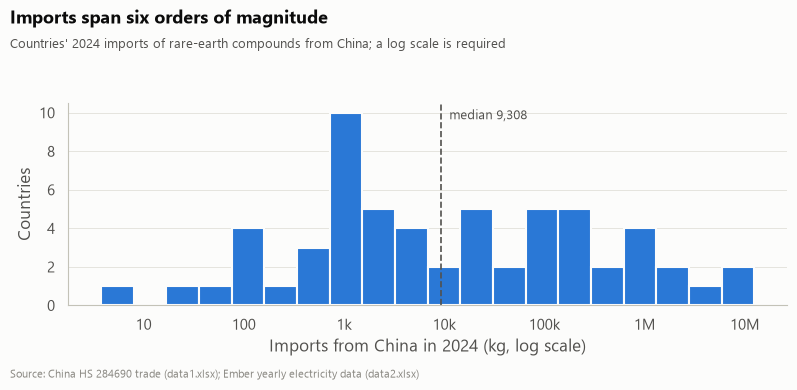

In [4]:
fig = ch.log_histogram(
    panel.loc[panel["year"] == 2024, "imports_from_china_kg"],
    "Imports from China in 2024 (kg, log scale)",
    "Imports span six orders of magnitude",
    "Countries' 2024 imports of rare-earth compounds from China; a log scale is required", SOURCE)
show(fig, "06_distribution")

### 1.2 Import growth, 2024

In [5]:
growth = st.growth_summary(panel.loc[panel["year"] == 2024, "import_growth_pct"])
pd.Series(growth).to_frame("2024 import growth")

,2024 import growth
n,52.00
median_pct,21.23
q1_pct,-48.63
q3_pct,181.39
share_growing,0.56
extreme_count,9.00
mean_pct,"11,367.87"


Growth rates from tiny bases explode: the **mean** is in the thousands of percent while the **median**
is modest. Growth should be modelled as a **log ratio** (`log(this year / last year)`) or winsorized,
never averaged raw.

### 1.3 Unit values (price per kg)

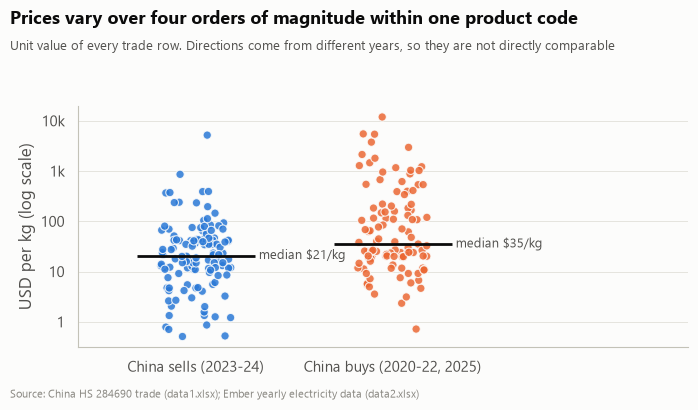

In [6]:
fig = ch.group_strip(
    trade, "unit_value_usd_per_kg", "trade_flow", ["Export", "Import"], "USD per kg (log scale)",
    "Prices vary over four orders of magnitude within one product code",
    "Unit value of every trade row. Directions come from different years, so they are not directly comparable",
    SOURCE, tick_labels=["China sells (2023-24)", "China buys (2020-22, 2025)"])
show(fig, "07_unit_values")

HS 284690 bundles many rare-earth compounds, from cheap bulk oxides to costly separated elements, so
**price per kg varies from under $1 to over $10,000**. Quantity in kg is therefore a better
measure of physical demand than value. The direction medians differ, but they come from different years,
so no conclusion about direction is drawn.

---
## 2. Bivariate analysis

### 2.1 Who buys from China? Concentration of demand

,2024
countries,60
top1_share,0.35
top5_share,0.83
top10_share,0.94
hhi,2054
level,highly concentrated


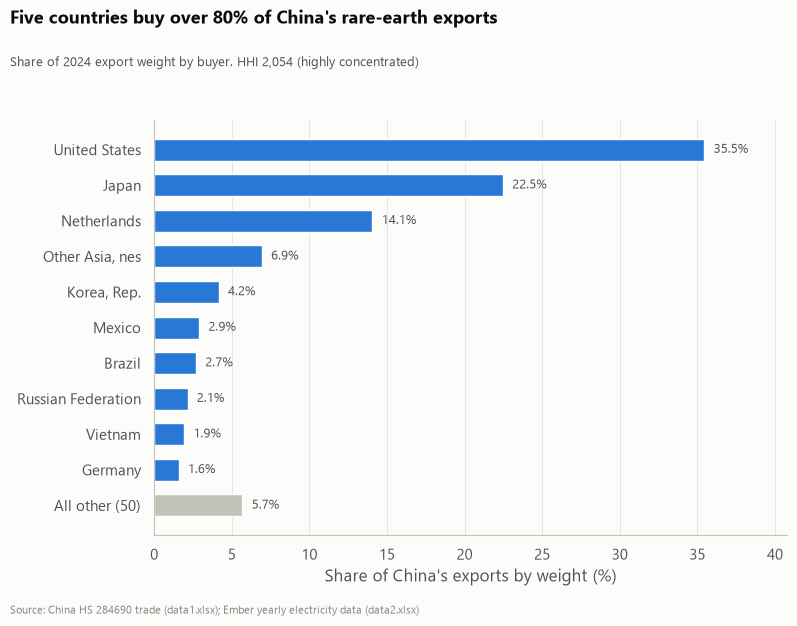

In [7]:
exports_2024 = trade[(trade["trade_flow"] == "Export") & (trade["year"] == 2024)]
conc = ex.concentration(exports_2024.groupby("partner")["quantity_kg"].sum())
shares = ex.market_shares(exports_2024, "partner", "quantity_kg", top=10)
display(pd.Series(conc).to_frame("2024"))
fig = ch.market_share_bars(
    shares, "Five countries buy over 80% of China's rare-earth exports",
    f"Share of 2024 export weight by buyer. HHI {conc['hhi']:,} ({conc['level']})", SOURCE)
show(fig, "01_concentration")

### 2.2 Volume vs value over time

,year,trade_flow,partners,quantity_kg,value_kusd,unit_value_usd_per_kg
0,2020,Import,25,"42,260,820.18","494,061.12",11.69
1,2021,Import,26,"44,752,941.07","1,063,323.65",23.76
2,2022,Import,25,"42,095,015.17","1,057,416.69",25.12
3,2023,Export,60,"33,392,492.55","512,019.29",15.33
4,2024,Export,60,"35,304,826.15","377,003.25",10.68
5,2025,Import,31,"75,888,981.83","1,550,090.05",20.43


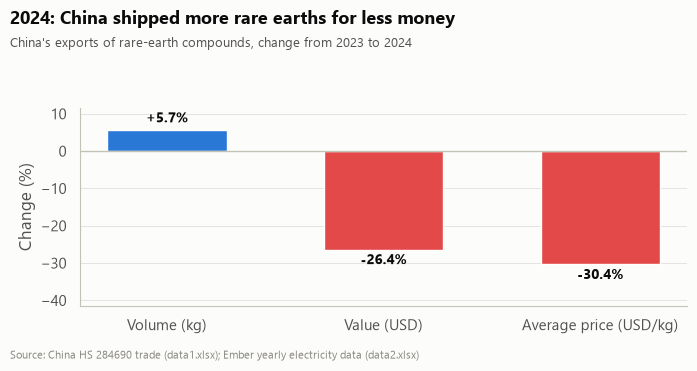

In [8]:
yearly = ex.yearly_trade(trade)
display(yearly)
change = ex.period_change(yearly, "Export", 2023, 2024)
change.index = ["Volume (kg)", "Value (USD)", "Average price (USD/kg)"]
fig = ch.change_bars(change, "2024: China shipped more rare earths for less money",
                     "China's exports of rare-earth compounds, change from 2023 to 2024", SOURCE)
show(fig, "02_price_drop")

### 2.3 Wind power trend

group,year,China,Other
0,2020,281.99,432.30
1,2021,328.97,474.56
2,2022,365.96,514.88
3,2023,441.89,550.59
4,2024,521.27,583.77
5,2025,640.63,611.19


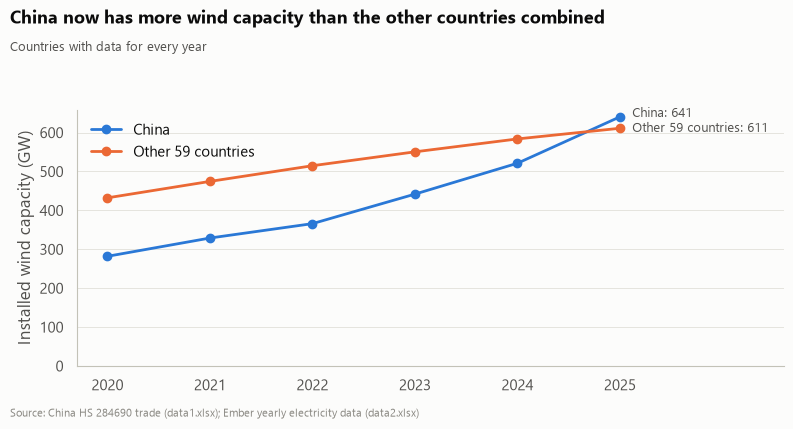

In [9]:
years = wind.groupby("country")["year"].nunique()
complete = wind[wind["country"].isin(years[years == years.max()].index)]
n = complete["country"].nunique()
if complete["country"].eq("China").any():
    groups = complete["country"].eq("China").map({True: "China", False: "Other"})
    series, labels = ["China", "Other"], ["China", f"Other {n - 1} countries"]
else:  # e.g. the synthetic sample has no China
    groups, series, labels = "All", ["All"], [f"All {n} countries"]
trend = (complete.assign(group=groups)
         .pivot_table(index="year", columns="group", values="wind_capacity_gw", aggfunc="sum")
         .reset_index())
display(trend)
last = trend.iloc[-1]
if "China" not in trend:
    title = "Wind capacity keeps climbing"
elif last["China"] > last["Other"]:
    title = "China now has more wind capacity than the other countries combined"
else:
    title = "Wind capacity keeps climbing, with China growing fastest"
fig = ch.line_trend(trend, "year", series, labels, "Installed wind capacity (GW)", title,
                    "Countries with data for every year", SOURCE)
show(fig, "03_wind_trend")

### 2.4 Pairwise relationships (Spearman, country-years with imports recorded)

In [10]:
pairs = [("imports_from_china_kg", "wind_capacity_gw"),
         ("imports_from_china_kg", "total_generation_twh"),
         ("wind_capacity_gw", "total_generation_twh"),
         ("imports_from_china_kg", "wind_share_pct")]
display(st.correlation_table(sample, pairs))
st.correlation_table(panel[panel["year"] == 2024], [("import_growth_pct", "wind_generation_change_twh")])

,x,y,method,n,r,p,strength
0,imports_from_china_kg,wind_capacity_gw,spearman,102,0.52,0.00,moderate positive
1,imports_from_china_kg,total_generation_twh,spearman,102,0.76,0.00,strong positive
2,wind_capacity_gw,total_generation_twh,spearman,102,0.61,0.00,strong positive
3,imports_from_china_kg,wind_share_pct,spearman,102,-0.00,0.99,very weak


,x,y,method,n,r,p,strength
0,import_growth_pct,wind_generation_change_twh,spearman,49,0.25,0.09,weak positive


Imports rise with wind capacity, but **even more with total electricity generation**, a measure of
country size. Imports are unrelated to the **share** of wind in a country's power mix. Growth in imports
and growth in wind are only weakly related in 2024, and not significantly so.

---
## 3. Multivariate analysis

### 3.1 Correlation matrix

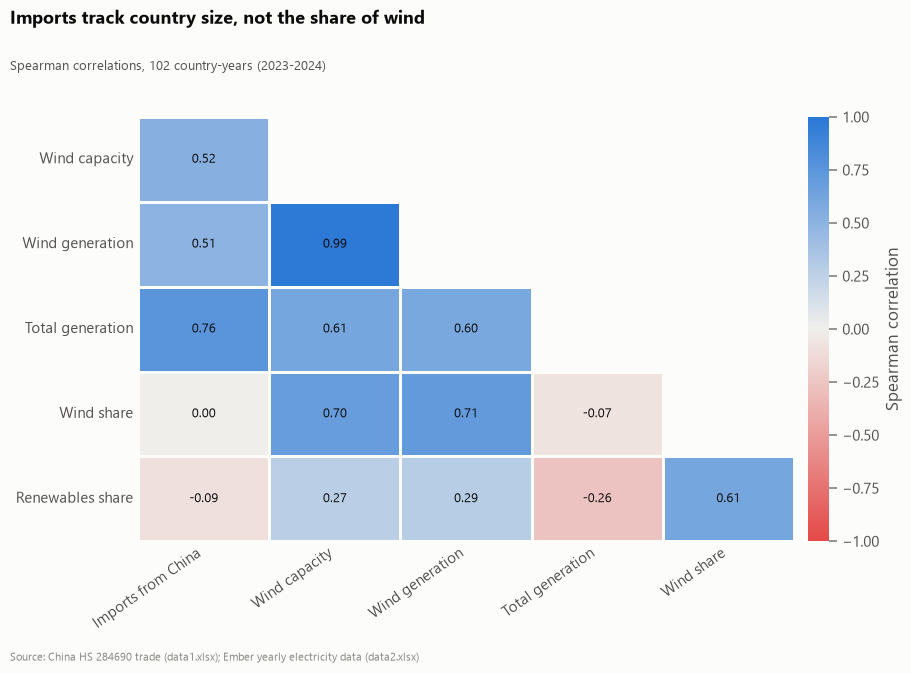

In [11]:
cols = ["imports_from_china_kg", "wind_capacity_gw", "wind_generation_twh",
        "total_generation_twh", "wind_share_pct", "renewables_share_pct"]
labels = ["Imports from China", "Wind capacity", "Wind generation", "Total generation",
          "Wind share", "Renewables share"]
matrix = st.correlation_matrix(sample, cols)
fig = ch.correlation_heatmap(matrix, labels, "Imports track country size, not the share of wind",
                             f"Spearman correlations, {len(sample)} country-years (2023-2024)", SOURCE)
show(fig, "05_correlations")

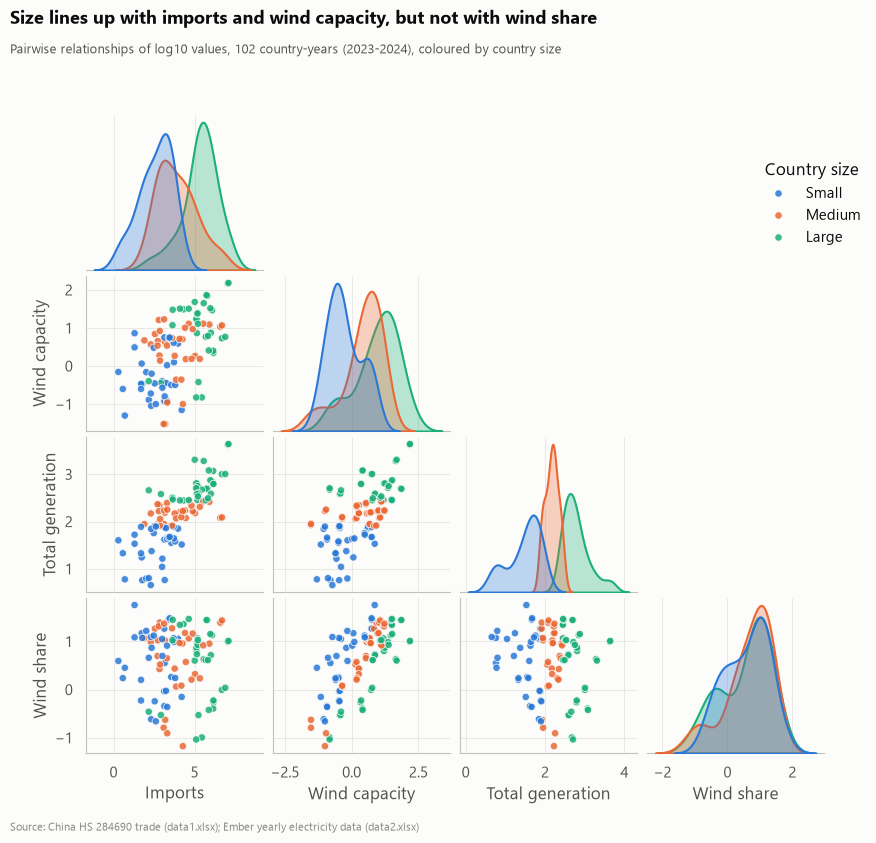

In [12]:
fig = ch.pair_plot(
    sample, ["imports_from_china_kg", "wind_capacity_gw", "total_generation_twh", "wind_share_pct"],
    ["Imports", "Wind capacity", "Total generation", "Wind share"], "size_group",
    ["Small", "Medium", "Large"],
    "Size lines up with imports and wind capacity, but not with wind share",
    f"Pairwise relationships of log10 values, {len(sample)} country-years (2023-2024), coloured by country size",
    SOURCE)
show(fig, "08_pairplot")

The pair plot shows the whole multivariate picture at once. Large countries (aqua) sit high on
imports, wind capacity and total generation alike. On **wind share**, the three size groups overlap
completely, and wind share shows no pattern against imports.

### 3.2 Is the wind link just country size?

Larger economies use more electricity, build more wind **and** import more of everything. Partial
correlation and regression remove size (total generation) to see what wind adds on its own.

In [13]:
raw = st.correlation(sample, "imports_from_china_kg", "wind_capacity_gw")
partial = st.partial_correlation(sample, "imports_from_china_kg", "wind_capacity_gw",
                                 ["total_generation_twh"])
pd.DataFrame([raw, partial])[["x", "y", "n", "r", "p", "strength"]].assign(
    analysis=["raw (Spearman)", "size removed (partial, log10)"]).set_index("analysis")

,x,y,n,r,p,strength
analysis,,,,,,
raw (Spearman),imports_from_china_kg,wind_capacity_gw,102,0.52,0.00,moderate positive
"size removed (partial, log10)",imports_from_china_kg,wind_capacity_gw,102,0.13,0.19,very weak


In [14]:
wind_only = st.fit_log_ols(sample, "imports_from_china_kg", ["wind_capacity_gw"])
with_size = st.fit_log_ols(sample, "imports_from_china_kg", ["wind_capacity_gw", "total_generation_twh"])
print(f"Model A, wind only:   R2 = {wind_only.rsquared:.2f}, n = {int(wind_only.nobs)}")
display(st.tidy_coefficients(wind_only))
print(f"Model B, wind + size: R2 = {with_size.rsquared:.2f}, n = {int(with_size.nobs)}")
st.tidy_coefficients(with_size)

Model A, wind only:   R2 = 0.29, n = 102


,coef,std_err,p,ci_low,ci_high
term,,,,,
Intercept,3.46,0.20,0.00,3.06,3.85
C(year)[T.2024],0.32,0.15,0.03,0.03,0.60
log_wind_capacity_gw,0.94,0.17,0.00,0.61,1.27


Model B, wind + size: R2 = 0.58, n = 102


,coef,std_err,p,ci_low,ci_high
term,,,,,
Intercept,0.03,0.52,0.96,-1.00,1.05
C(year)[T.2024],0.24,0.14,0.09,-0.04,0.51
log_wind_capacity_gw,0.20,0.16,0.22,-0.12,0.52
log_total_generation_twh,1.74,0.25,0.00,1.26,2.22


Both models use log10 values, so coefficients are **elasticities**, with standard errors clustered by
country and year fixed effects.
- **Model A:** a 1% larger wind fleet goes with about **0.9% more imports**.
- **Model B:** once size is added, the wind elasticity falls to about **0.2** and is **not significant**.
  Size carries the effect (elasticity about **1.7**), and R² roughly doubles.

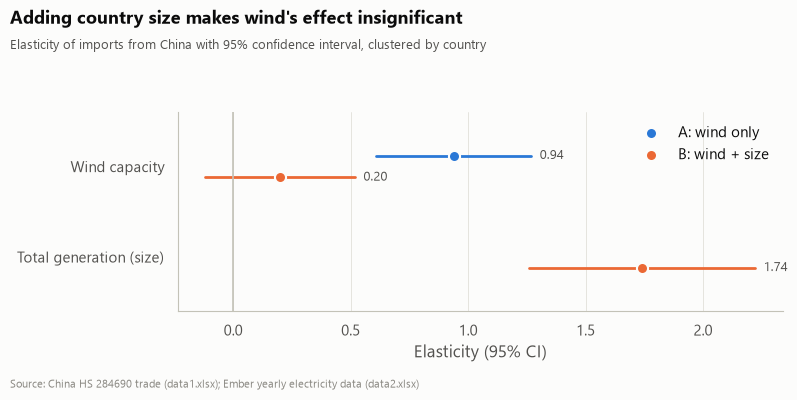

In [15]:
fig = ch.coefficient_plot(
    {"A: wind only": st.tidy_coefficients(wind_only), "B: wind + size": st.tidy_coefficients(with_size)},
    {"log_wind_capacity_gw": "Wind capacity", "log_total_generation_twh": "Total generation (size)"},
    "Adding country size makes wind's effect insignificant",
    "Elasticity of imports from China with 95% confidence interval, clustered by country", SOURCE)
show(fig, "09_elasticities")

**Regression diagnostics (Model B).** Are the model's assumptions met?

In [16]:
st.regression_diagnostics(with_size)

,assumption,test,value,ok,meaning
0,Equal variance of residuals,Breusch-Pagan,0.85,True,no heteroskedasticity
1,Residuals normally distributed,Jarque-Bera,0.71,True,normal
2,No multicollinearity,max VIF (log_wind_capacity_gw),1.60,True,VIF < 5


All three assumptions hold:
- **Equal variance:** residual variance is equal across fitted values.
- **Normal residuals:** residuals are normally distributed.
- **No collinearity:** wind capacity and size aren't so correlated that their effects can't be
  separated (VIF well below 5).

So wind's insignificance in Model B is a real result, not an artifact of collinearity or a
misspecified model.

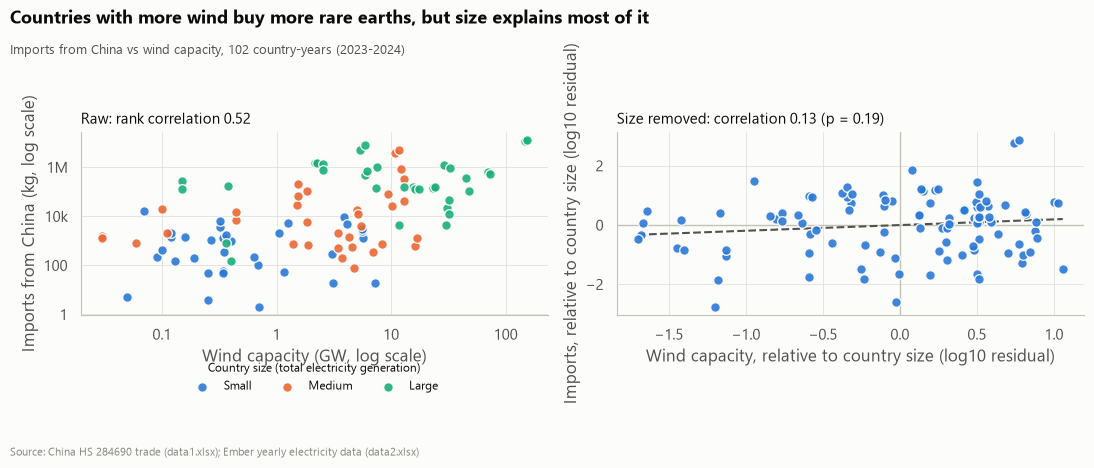

In [17]:
logged = sample[["imports_from_china_kg", "wind_capacity_gw", "total_generation_twh"]].apply(st.log10_positive)
resid = pd.DataFrame({
    "x_resid": st.residualize(logged, "wind_capacity_gw", ["total_generation_twh"]),
    "y_resid": st.residualize(logged, "imports_from_china_kg", ["total_generation_twh"]),
})
fig = ch.confounding_scatter(
    sample, "wind_capacity_gw", "imports_from_china_kg", "size_group", ["Small", "Medium", "Large"],
    resid, f"Raw: rank correlation {raw['r']:.2f}",
    f"Size removed: correlation {partial['r']:.2f} (p = {partial['p']:.2f})",
    "Countries with more wind buy more rare earths, but size explains most of it",
    f"Imports from China vs wind capacity, {len(sample)} country-years (2023-2024)", SOURCE,
    "Wind capacity (GW, log scale)", "Imports from China (kg, log scale)")
show(fig, "04_size_confound")

---
## 4. Hypothesis testing

Five hypotheses, each with a test suited to skewed data. Because five tests are run, p-values are
**Holm-adjusted** to keep the overall chance of a false positive at 5%.

In [18]:
h1 = st.correlation(sample, "imports_from_china_kg", "wind_capacity_gw")
h2 = st.partial_correlation(sample, "imports_from_china_kg", "wind_capacity_gw", ["total_generation_twh"])
h3 = st.correlation(panel[panel["year"] == 2024], "import_growth_pct", "wind_generation_change_twh")
exports = trade[trade["trade_flow"] == "Export"]
h4 = st.paired_change(exports, "partner", "year", "unit_value_usd_per_kg", 2023, 2024)
h5 = st.compare_groups(sample, "imports_from_china_kg", "size_group", ["Small", "Medium", "Large"])
tests = st.hypothesis_table([
    {"hypothesis": "H1: imports rise with wind capacity", "test": "Spearman correlation",
     "statistic": h1["r"], "p": h1["p"], "n": h1["n"]},
    {"hypothesis": "H2: wind matters after controlling for size", "test": "Partial correlation (log10)",
     "statistic": h2["r"], "p": h2["p"], "n": h2["n"]},
    {"hypothesis": "H3: faster wind growth, faster import growth (2024)", "test": "Spearman correlation",
     "statistic": h3["r"], "p": h3["p"], "n": h3["n"]},
    {"hypothesis": "H4: buyers paid less per kg in 2024 than 2023", "test": "Wilcoxon signed-rank (paired)",
     "statistic": h4["median_change_pct"], "p": h4["p"], "n": h4["n"]},
    {"hypothesis": "H5: imports differ by country size", "test": "Kruskal-Wallis",
     "statistic": h5["statistic"], "p": h5["p"], "n": h5["n"]},
])
tests

,hypothesis,test,statistic,p,n,p_holm,result
0,H1: imports rise with wind capacity,Spearman correlation,0.52,0.00,102,0.00,Supported
1,H2: wind matters after controlling for size,Partial correlation (log10),0.13,0.19,102,0.22,Not supported
2,"H3: faster wind growth, faster import growth (...",Spearman correlation,0.25,0.09,49,0.22,Not supported
3,H4: buyers paid less per kg in 2024 than 2023,Wilcoxon signed-rank (paired),-10.99,0.07,52,0.22,Not supported
4,H5: imports differ by country size,Kruskal-Wallis,50.58,0.00,102,0.00,Supported


In [19]:
print(f"H4 detail: same buyer in both years, median price change {h4['median_change_pct']:+.1f}%, "
      f"{h4['share_falling']:.0%} of {h4['n']} buyers paid less")
print("H5 medians (kg):", {k: f"{v:,.0f}" for k, v in h5["medians"].items()})
ci = st.bootstrap_ci(exports_2024.groupby("partner")["quantity_kg"].sum(), st.top_share)
print(f"Top-5 buyers' share of 2024 exports: {ci['estimate']:.1%} "
      f"(95% bootstrap CI {ci['ci_low']:.1%} to {ci['ci_high']:.1%})")

H4 detail: same buyer in both years, median price change -11.0%, 62% of 52 buyers paid less
H5 medians (kg): {'Small': '705', 'Medium': '5,040', 'Large': '229,432'}
Top-5 buyers' share of 2024 exports: 83.1% (95% bootstrap CI 60.7% to 91.3%)


**Results**
- **H1 is supported:** countries with more wind import more.
- **H2 isn't:** the link disappears once size is held constant (see also Model B).
- **H3 isn't:** faster wind growth didn't go with faster import growth in 2024.
- **H4 isn't**, which corrects a first impression. The *aggregate* average price fell 30% (section
  2.2), but for the same buyer in both years the median price fell only about 11%, and that change
  isn't significant. Much of the aggregate fall is a **mix effect**: which buyers bought how much.
- **H5 is supported, strongly:** large economies import hundreds of times more than small ones.
- **Concentration:** even the lower end of the bootstrap interval shows the top five buyers above 60%.

---
## 5. Findings that inform the modeling approach

| # | Finding | Implication for modeling (Assignment 6) |
|---|---|---|
| 1 | All size measures are skewed 4–7 | Model **log** quantities; report elasticities |
| 2 | Wind capacity's link with imports is mostly **country size** | Always **control for size** (total generation; add GDP if available); wind alone overstates its effect |
| 3 | Imports are unrelated to the wind **share** of the power mix | Use absolute capacity or capacity **additions**, not shares |
| 4 | Growth rates explode from small bases (mean in the thousands of %) | Model growth as a **log ratio**, or set a minimum base |
| 5 | Imports exist only for 2023–2024 | Re-download `data1.xlsx` with exports for all years before panel or time-series models; for now n = 102 country-years in a cross-section |
| 6 | Price per kg varies more than 1,000-fold within HS 284690 | Use **kg** as the demand measure; treat value separately |
| 7 | Five buyers hold over 80% of volume | Check that results don't hinge on the US and Japan (re-estimate without them) |
| 8 | The aggregate price drop is mostly mix (H4 not supported per buyer) | Model prices per buyer, or decompose price vs mix; don't use aggregate unit value as "the price" |
| 9 | Regression assumptions hold; log data is normal | Log-log OLS with clustered errors is a sound baseline for Assignment 6 |

Full write-up: [`docs/statistical_analysis_report.md`](../docs/statistical_analysis_report.md). Executive summary:
[`docs/executive_summary.md`](../docs/executive_summary.md).